In [1]:
# IMPORTING LIBRARIES

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np



In [2]:
# LOADING THE DATASET

df = pd.read_csv("../data/in-between/german-credit_risk_in-between_dataset.csv")
df

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,0
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,1
2,2,49,male,1,own,little,NaN,2096,12,education,0
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,0
4,4,53,male,2,free,little,little,4870,24,car,1
...,...,...,...,...,...,...,...,...,...,...,...
949,949,31,male,2,own,moderate,NaN,3621,24,radio/TV,1
950,950,40,male,0,own,little,moderate,3590,18,business,0
951,951,24,male,2,own,little,little,2145,36,business,1
952,952,28,female,2,rent,quite rich,moderate,4113,24,car,1


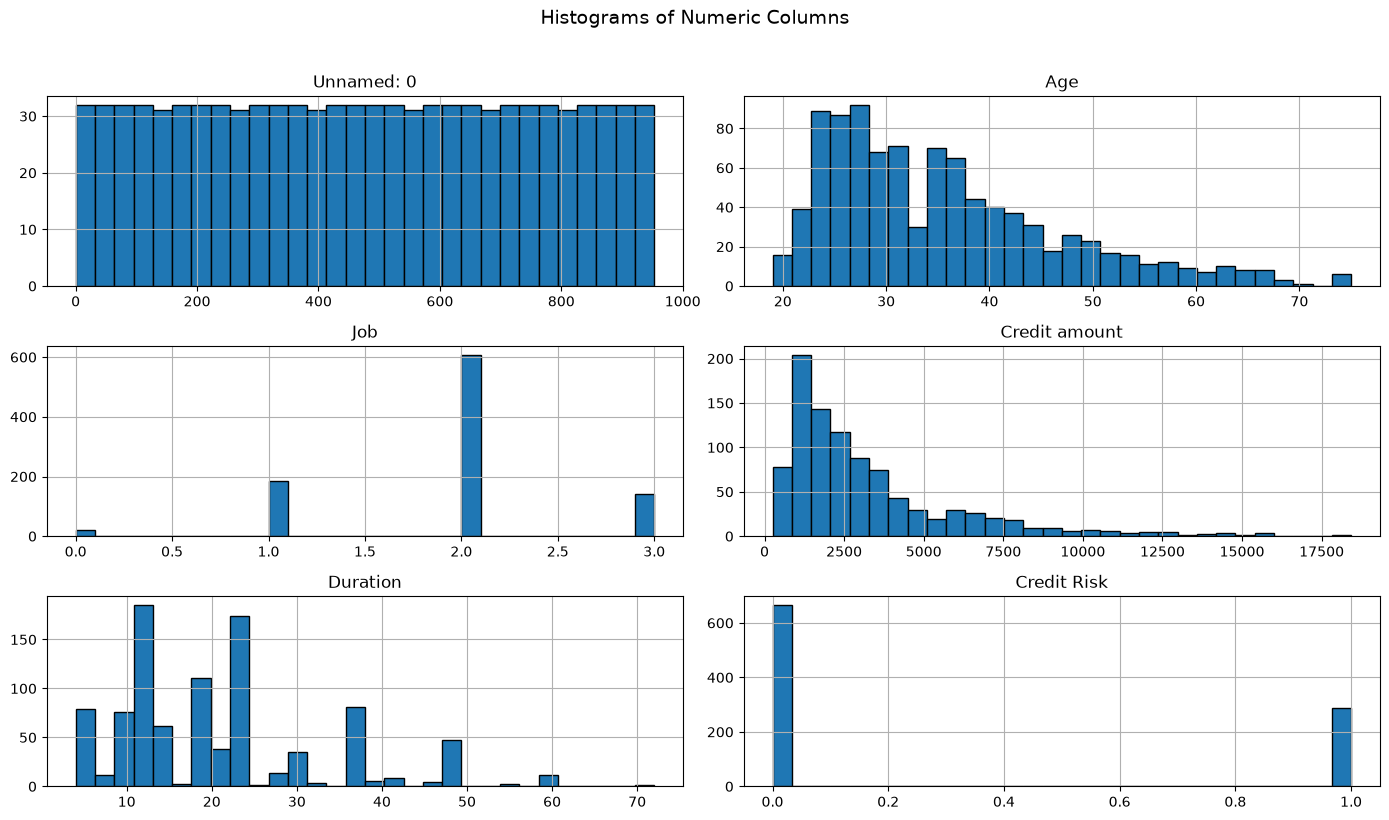

In [3]:
# DISTRIBUTION THROUGH HISTOGRAMS OF NUMERIC COLUMNS

numeric_df = df.select_dtypes(include='number')
numeric_df.hist(bins=30, figsize=(14, 8), edgecolor='black')
plt.suptitle('Histograms of Numeric Columns', y=1.02, fontsize=14)
plt.tight_layout()

# SAVING FIGURE 
PATH = '../reports/figures/histograms_numeric_columns.png'
plt.savefig(PATH, dpi=300, bbox_inches='tight')

plt.show()

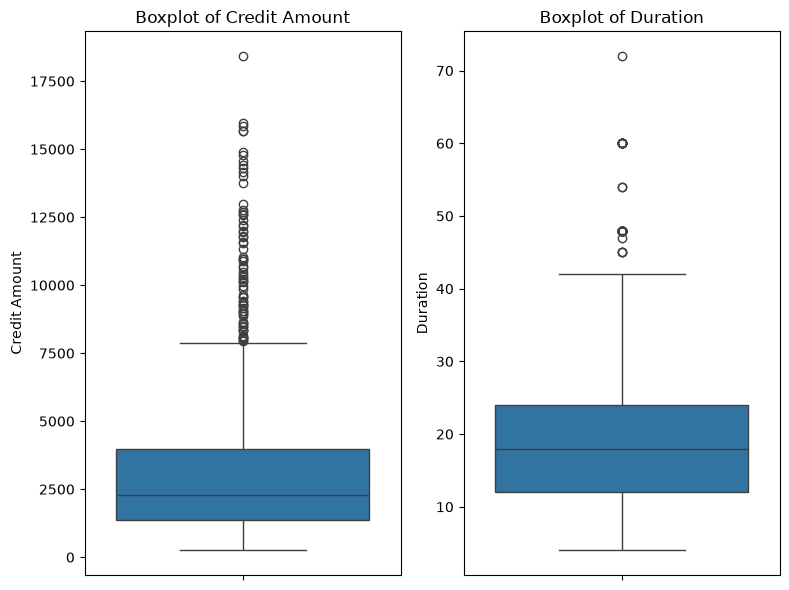

In [4]:
# BOX-PLOT 

figs,axes=plt.subplots(1,2,figsize=(8,6))

sns.boxplot(y=df['Credit amount'],ax=axes[0])
axes[0].set_title('Boxplot of Credit Amount')
plt.tight_layout()
axes[0].set_ylabel('Credit Amount')

sns.boxplot(y=df['Duration'],ax=axes[1])
axes[1].set_title('Boxplot of Duration')
plt.tight_layout()
axes[1].set_ylabel('Duration')

plt.savefig('../reports/figures/boxplots_credit_duration.png', dpi=300, bbox_inches='tight')
plt.show()

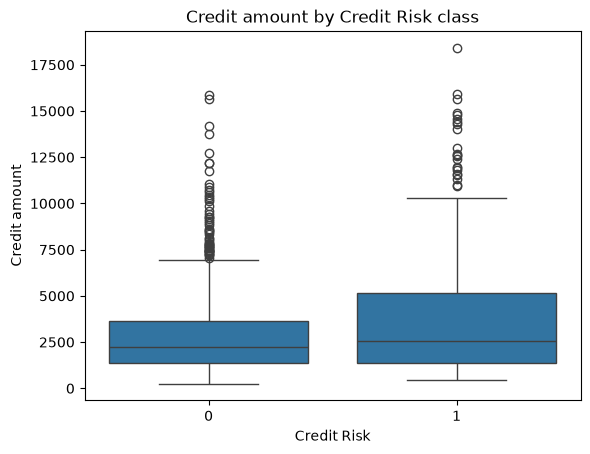

--------------------------------------------------
Credit Risk
0    2994.517293
1    3933.975779
Name: Credit amount, dtype: float64


In [5]:
# Compare Credit amount features with the target

sns.boxplot(data=df, x="Credit Risk", y="Credit amount")
plt.title("Credit amount by Credit Risk class")
plt.savefig('../reports/figures/boxplot_credit_amount_by_credit_risk.png', dpi=300, bbox_inches='tight')
plt.show()
print('-'*50)
print(df.groupby("Credit Risk")["Credit amount"].mean())

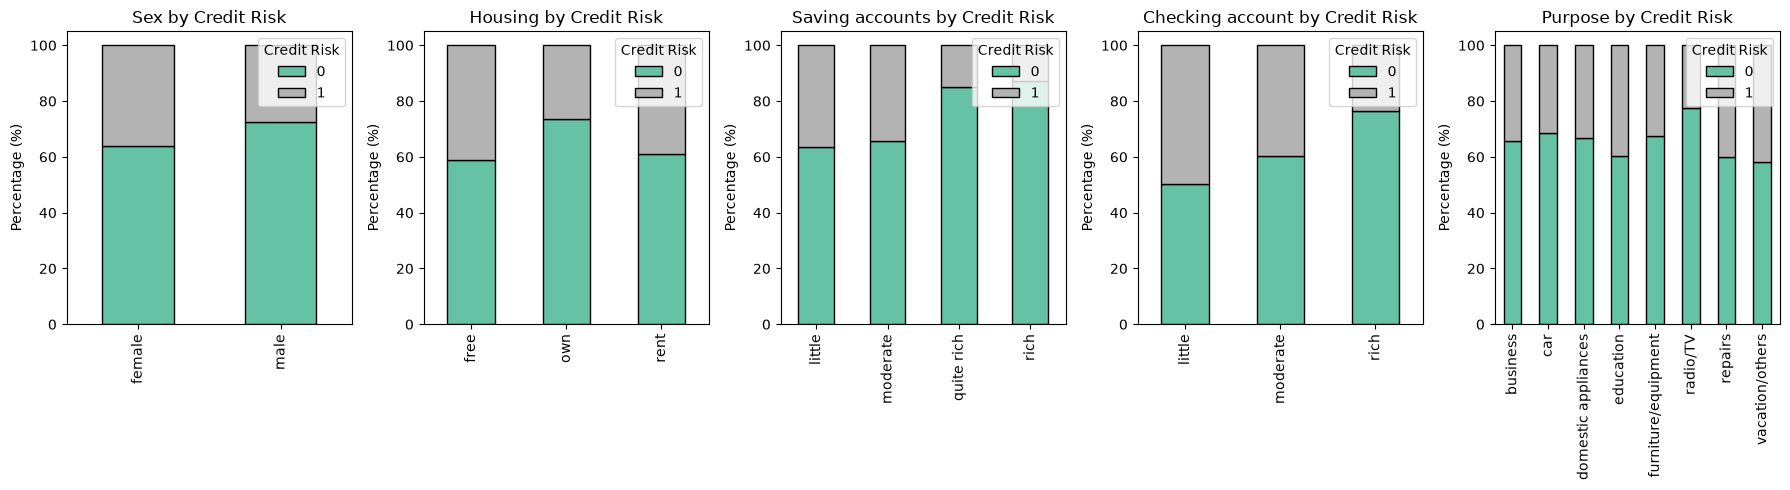

In [6]:
# DISTRIBUTION OF CATEGORICAL VARIABLES USING CROSSTAB

cat_cols = df.select_dtypes(include=["str", "object", "category"]).columns
target = 'Credit Risk'

fig, axes = plt.subplots(1, len(cat_cols), figsize=(18, 5))

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df[col], df[target], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axes[i], colormap='Set2', edgecolor='black')
    
    axes[i].set_title(f'{col} by {target}')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=90)
    axes[i].legend(title=target, loc='upper right')

plt.savefig('../reports/figures/categorical_distribution.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [7]:
# DISTRIBUTION OF CATEGORICAL VARIABLES

cat_cols = df.select_dtypes(include=["str", "object", "category"]).columns

for col in cat_cols:

    print(df[col].value_counts(dropna=False))
    print("-" * 40) 

Sex
male      656
female    298
Name: count, dtype: int64
----------------------------------------
Housing
own     680
rent    169
free    105
Name: count, dtype: int64
----------------------------------------
Saving accounts
little        576
NaN           175
moderate       96
quite rich     60
rich           47
Name: count, dtype: int64
----------------------------------------
Checking account
NaN         378
little      261
moderate    256
rich         59
Name: count, dtype: int64
----------------------------------------
Purpose
car                    322
radio/TV               262
furniture/equipment    175
business                93
education               58
repairs                 20
domestic appliances     12
vacation/others         12
Name: count, dtype: int64
----------------------------------------


In [8]:
# DISTRIBUTION OF CATEGORICAL FEATURES vs CREDIT RISK

cat_cols = df.select_dtypes(include=["str", "object", "category"]).columns 
target = 'Credit Risk'

for col in cat_cols:
    print(f"\n--- {col} vs {target} (%) ---")
    ct = pd.crosstab(df[col], df[target], normalize='index') * 100
    print(ct.round(2))
    print("-" * 40) 


--- Sex vs Credit Risk (%) ---
Credit Risk      0      1
Sex                      
female       63.76  36.24
male         72.41  27.59
----------------------------------------

--- Housing vs Credit Risk (%) ---
Credit Risk      0      1
Housing                  
free         59.05  40.95
own          73.53  26.47
rent         60.95  39.05
----------------------------------------

--- Saving accounts vs Credit Risk (%) ---
Credit Risk          0      1
Saving accounts              
little           63.72  36.28
moderate         65.62  34.38
quite rich       85.00  15.00
rich             87.23  12.77
----------------------------------------

--- Checking account vs Credit Risk (%) ---
Credit Risk           0      1
Checking account              
little            50.19  49.81
moderate          60.16  39.84
rich              76.27  23.73
----------------------------------------

--- Purpose vs Credit Risk (%) ---
Credit Risk              0      1
Purpose                          
busine

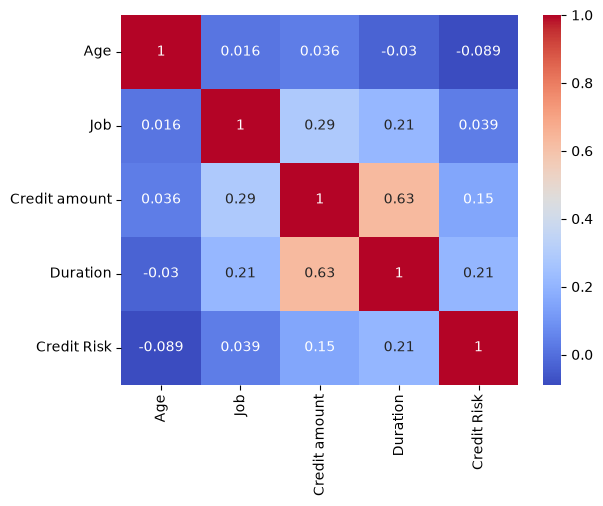

In [9]:
# Correlation

corr =df.iloc[:,1:].select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.savefig('../reports/figures/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()